In [42]:
import pandas as pd
import numpy as np


In [43]:
sample0_filepath = "../Data/training_data/mixed_samples/0healthy.npy"
sample0 = np.load(sample0_filepath)
sample0.shape

# (frame, points, position)
# (10, 18000, 4)


(10, 18000, 4)

In [44]:
sample0

array([[[-20.157444  ,  17.62280464,   8.63055611,   2.        ],
        [-20.09103012,  17.62147141,   8.63197422,   2.        ],
        [-20.10420418,  17.62444115,   8.61793327,   2.        ],
        ...,
        [-17.84309578, -33.76960754,  53.19683838,   1.        ],
        [-16.25856209, -35.0315094 ,  57.05285645,   1.        ],
        [-15.38268089, -35.53833008,  59.0874176 ,   1.        ]],

       [[-19.19090843,  17.49430275,   9.2532053 ,   2.        ],
        [-19.11496544,  17.52137566,   9.26454735,   2.        ],
        [-19.10906029,  17.52939224,   9.25193214,   2.        ],
        ...,
        [-17.47473717, -31.39459229,  49.87592697,   1.        ],
        [-16.00337601, -32.55651855,  53.38047791,   1.        ],
        [-15.19591618, -32.96632385,  55.38721085,   1.        ]],

       [[-18.31469727,  14.26771927,   9.15201092,   2.        ],
        [-18.25457001,  14.28464699,   9.16969109,   2.        ],
        [-18.26982689,  14.30463123,   9.16434

In [45]:
import pymeshlab

ms = pymeshlab.MeshSet()

In [46]:
import plotly.express as px

one_frame = sample0[0, :, :]

for i in range(0, 10, 3):
    frame = sample0[i, :, :]
    px.scatter_3d(x=frame[:,0], y=frame[:,1], z=frame[:,2], color=frame[:,3], width=400, height=400).update_traces(marker_size=2).show()

# px.scatter_3d(x=one_frame[:,0], y=one_frame[:,1], z=one_frame[:,2], color=one_frame[:,3]).update_traces(marker_size=2).show()


In [47]:
tabular_filepath = "../Data/training_data/mixed_demographics.csv"


tabular = pd.read_csv(tabular_filepath)

{'whiskers': [<matplotlib.lines.Line2D at 0x3106c78c0>,
 'caps': [<matplotlib.lines.Line2D at 0x3106c7b60>,
 'boxes': [<matplotlib.lines.Line2D at 0x3106c7770>,
 'medians': [<matplotlib.lines.Line2D at 0x3106c7e00>,
 'fliers': [<matplotlib.lines.Line2D at 0x310774050>,
 'means': []}

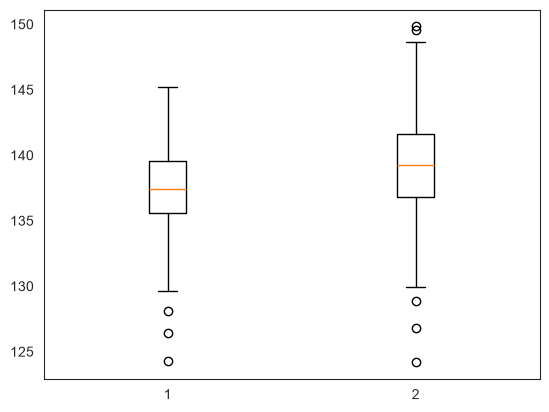

In [48]:
import matplotlib.pyplot as plt

healthy = tabular[tabular['MI'] == "healthy"]
pMI = tabular[tabular['MI'] == "pMI"]

plt.boxplot((healthy['systolic_BP'], pMI['systolic_BP']))


{'whiskers': [<matplotlib.lines.Line2D at 0x310777a10>,
 'caps': [<matplotlib.lines.Line2D at 0x310777cb0>,
 'boxes': [<matplotlib.lines.Line2D at 0x3107778c0>,
 'medians': [<matplotlib.lines.Line2D at 0x3107f8050>,
 'fliers': [<matplotlib.lines.Line2D at 0x3107f81a0>,
 'means': []}

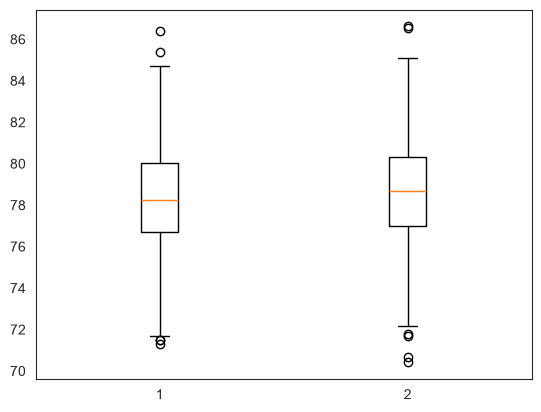

In [49]:
plt.boxplot((healthy['diastolic_BP'], pMI['diastolic_BP']))


{'whiskers': [<matplotlib.lines.Line2D at 0x310954980>,
 'caps': [<matplotlib.lines.Line2D at 0x310954c20>,
 'boxes': [<matplotlib.lines.Line2D at 0x310954830>,
 'medians': [<matplotlib.lines.Line2D at 0x310954ec0>,
 'fliers': [<matplotlib.lines.Line2D at 0x310955010>,
 'means': []}

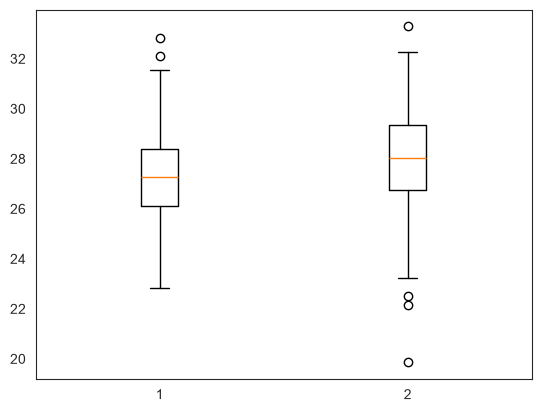

In [50]:
plt.boxplot((healthy['BMI'], pMI['BMI']))


# PCA Exploration

In [51]:
from sklearn.decomposition import PCA


In [52]:
one_frame.flatten()

array([-20.157444  ,  17.62280464,   8.63055611, ..., -35.53833008,
        59.0874176 ,   1.        ], shape=(72000,))

In [53]:
import os

folder = "../Data/training_data/mixed_samples/"

train = os.listdir(folder)

data = np.ndarray((len(train), 72000))

for i, file in enumerate(train):
    sample = np.load(os.path.join(folder, file))

    frame_one = sample[0, :, :]
    frame_two = sample[5, :, :]

    velocity = frame_two - frame_one

    data[i] = velocity.flatten()

data

array([[ 1.46965694, -1.54838085, -0.93621349, ...,  2.24298096,
        -2.73532867,  0.        ],
       [-0.85206127, -1.90216923,  0.62355614, ...,  2.8954277 ,
        -2.82943344,  0.        ],
       [ 0.2739315 , -1.76142979, -0.55531263, ...,  2.39876175,
        -6.72915649,  0.        ],
       ...,
       [ 0.78326607, -1.34990406, -0.96045589, ...,  1.69658661,
        -3.04452133,  0.        ],
       [ 2.52802277, -0.08370018,  0.3988905 , ...,  4.4781723 ,
        -7.37137222,  0.        ],
       [ 0.53979874, -0.82697487,  0.36641407, ...,  2.40746689,
        -4.58956146,  0.        ]], shape=(900, 72000))

In [54]:


pca = PCA()
pca.fit(data)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [55]:
sd = np.sqrt(pca.explained_variance_)
prop = pca.explained_variance_ratio_
cum = np.cumsum(prop)

summary = pd.DataFrame({
    "Std dev.": sd,
    "Prop. var": prop,
    "Cum. prop": cum
}, index=[f"Comp.{i+1}" for i in range(len(sd))]).round(6)
summary

,Std dev.,Prop. var,Cum. prop
Comp.1,546.638794,0.365799,0.365799
Comp.2,325.408636,0.129628,0.495428
Comp.3,261.234975,0.083542,0.578969
Comp.4,151.122576,0.027958,0.606927
Comp.5,103.234793,0.013047,0.619974
...,...,...,...
Comp.896,0.018594,0.000000,1.000000
Comp.897,0.016430,0.000000,1.000000
Comp.898,0.013868,0.000000,1.000000
Comp.899,0.009352,0.000000,1.000000


After 61 PCA, have 99% of the cumulative variance. 

In [66]:
import seaborn as sns

scores = pca.transform(data)
scores_df = pd.DataFrame(scores, columns=[f"PC{i+1}" for i in range(scores.shape[1])])

scores_df = scores_df.drop([f"PC{i+1}" for i in range(5, scores.shape[1])], axis=1)
scores_df['MI'] = tabular["MI"]
scores_df['age'] = tabular["age"]
scores_df['BMI'] = tabular["BMI"]
scores_df

,PC1,PC2,PC3,PC4,PC5,MI,age,BMI
0,369.834213,-427.468076,-9.788050,95.086015,14.762851,healthy,62.593012,25.312186
1,234.802361,-291.678622,-4.880056,-113.988642,-144.487286,healthy,58.037959,32.100795
2,-290.890452,162.840908,-8.047241,-68.724923,38.719656,pMI,65.840496,26.099055
3,485.504896,-343.334316,-4.179383,-106.848618,5.918309,pMI,68.518300,27.672836
4,-2231.544312,-1086.891442,-9.334786,34.912992,-150.907821,healthy,55.591381,27.266429
...,...,...,...,...,...,...,...,...
895,656.841521,-670.663105,-2.743993,-153.306890,43.307819,pMI,68.332345,26.048104
896,-245.659869,254.260287,-9.063941,-44.322555,33.414382,healthy,64.392429,28.965176
897,288.350399,-330.297444,-11.348215,123.581591,-42.754402,pMI,63.653352,26.534891
898,122.669715,39.756244,-3.283633,-129.626729,41.679807,pMI,66.775260,27.679240


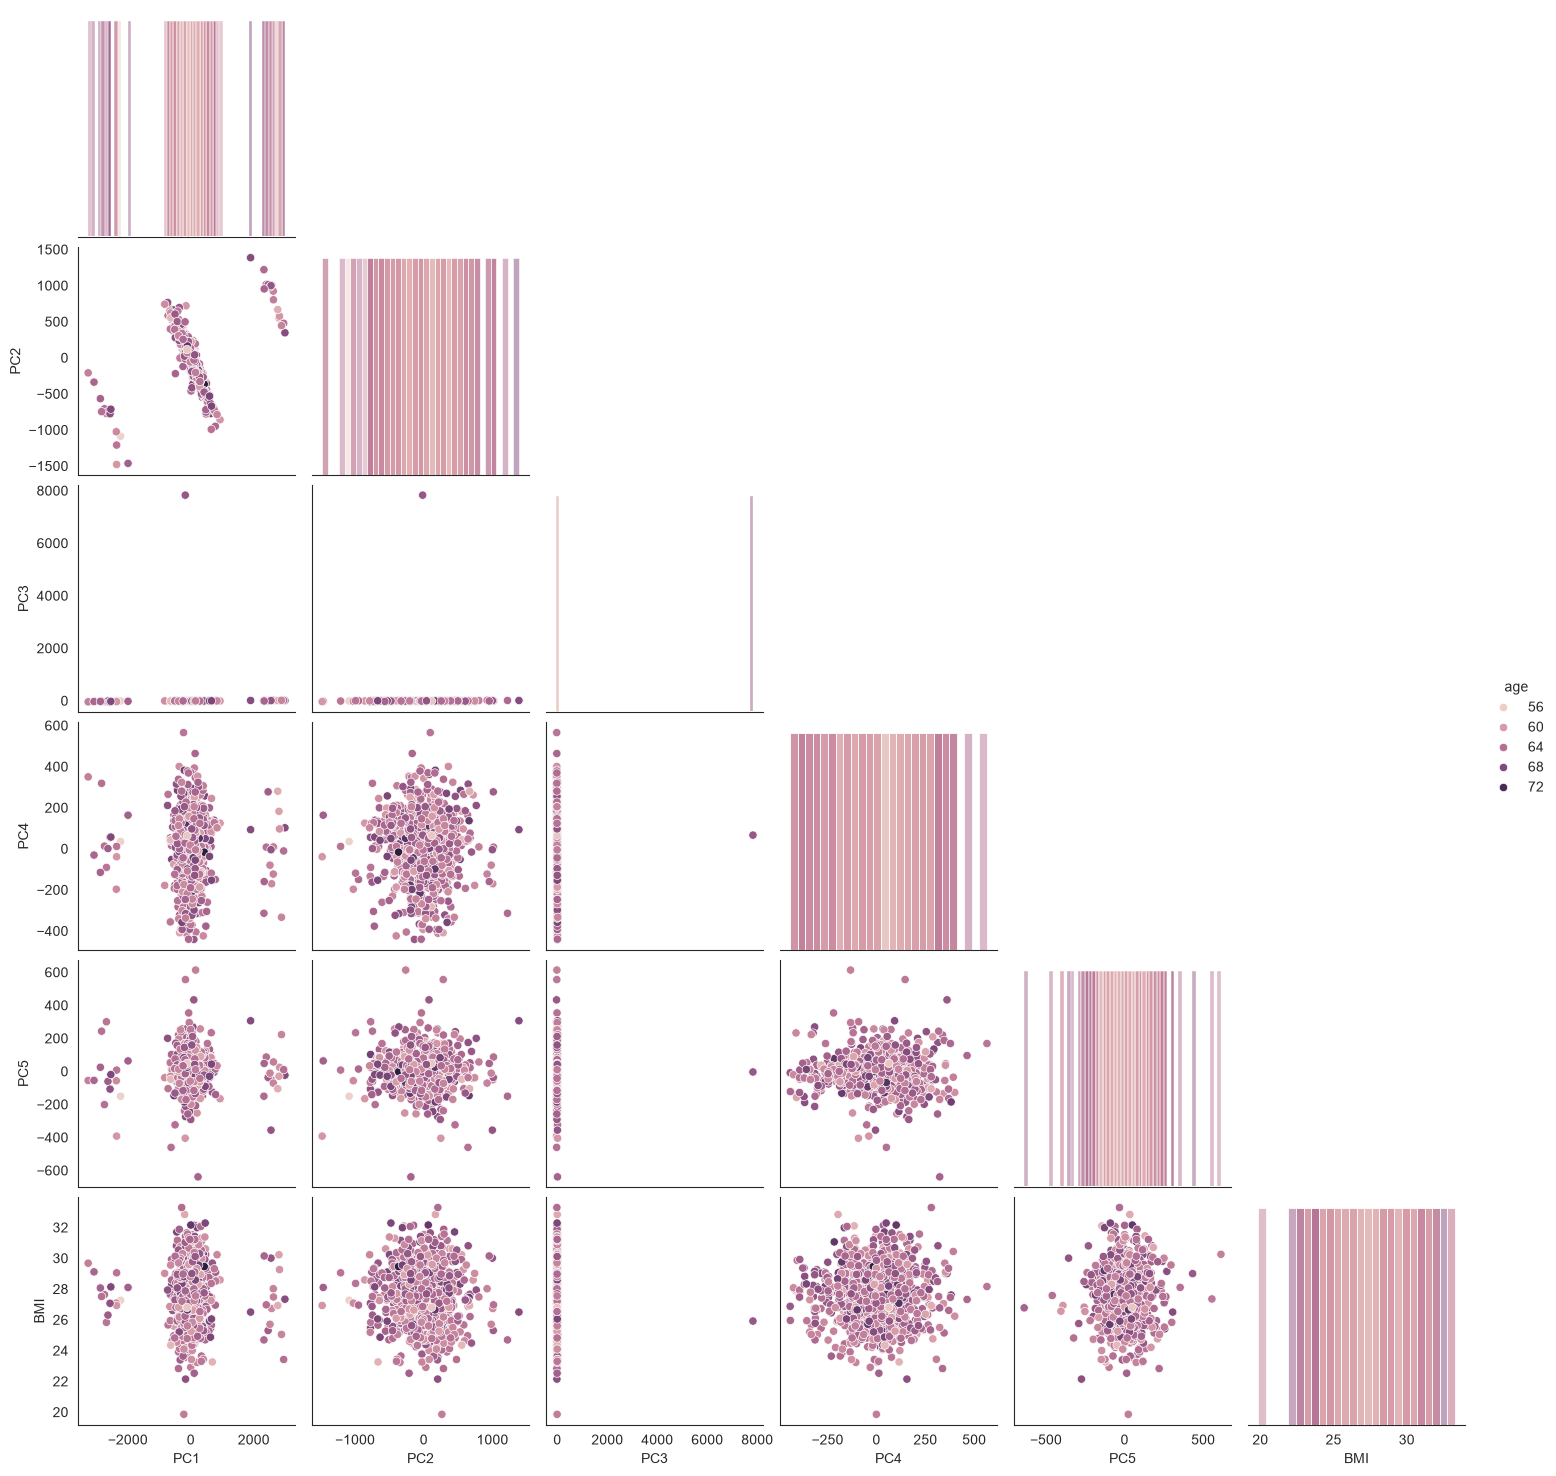

In [67]:
sns.set_style("white")
sns.pairplot(scores_df, diag_kind="hist", corner=True, hue='age')
plt.show()

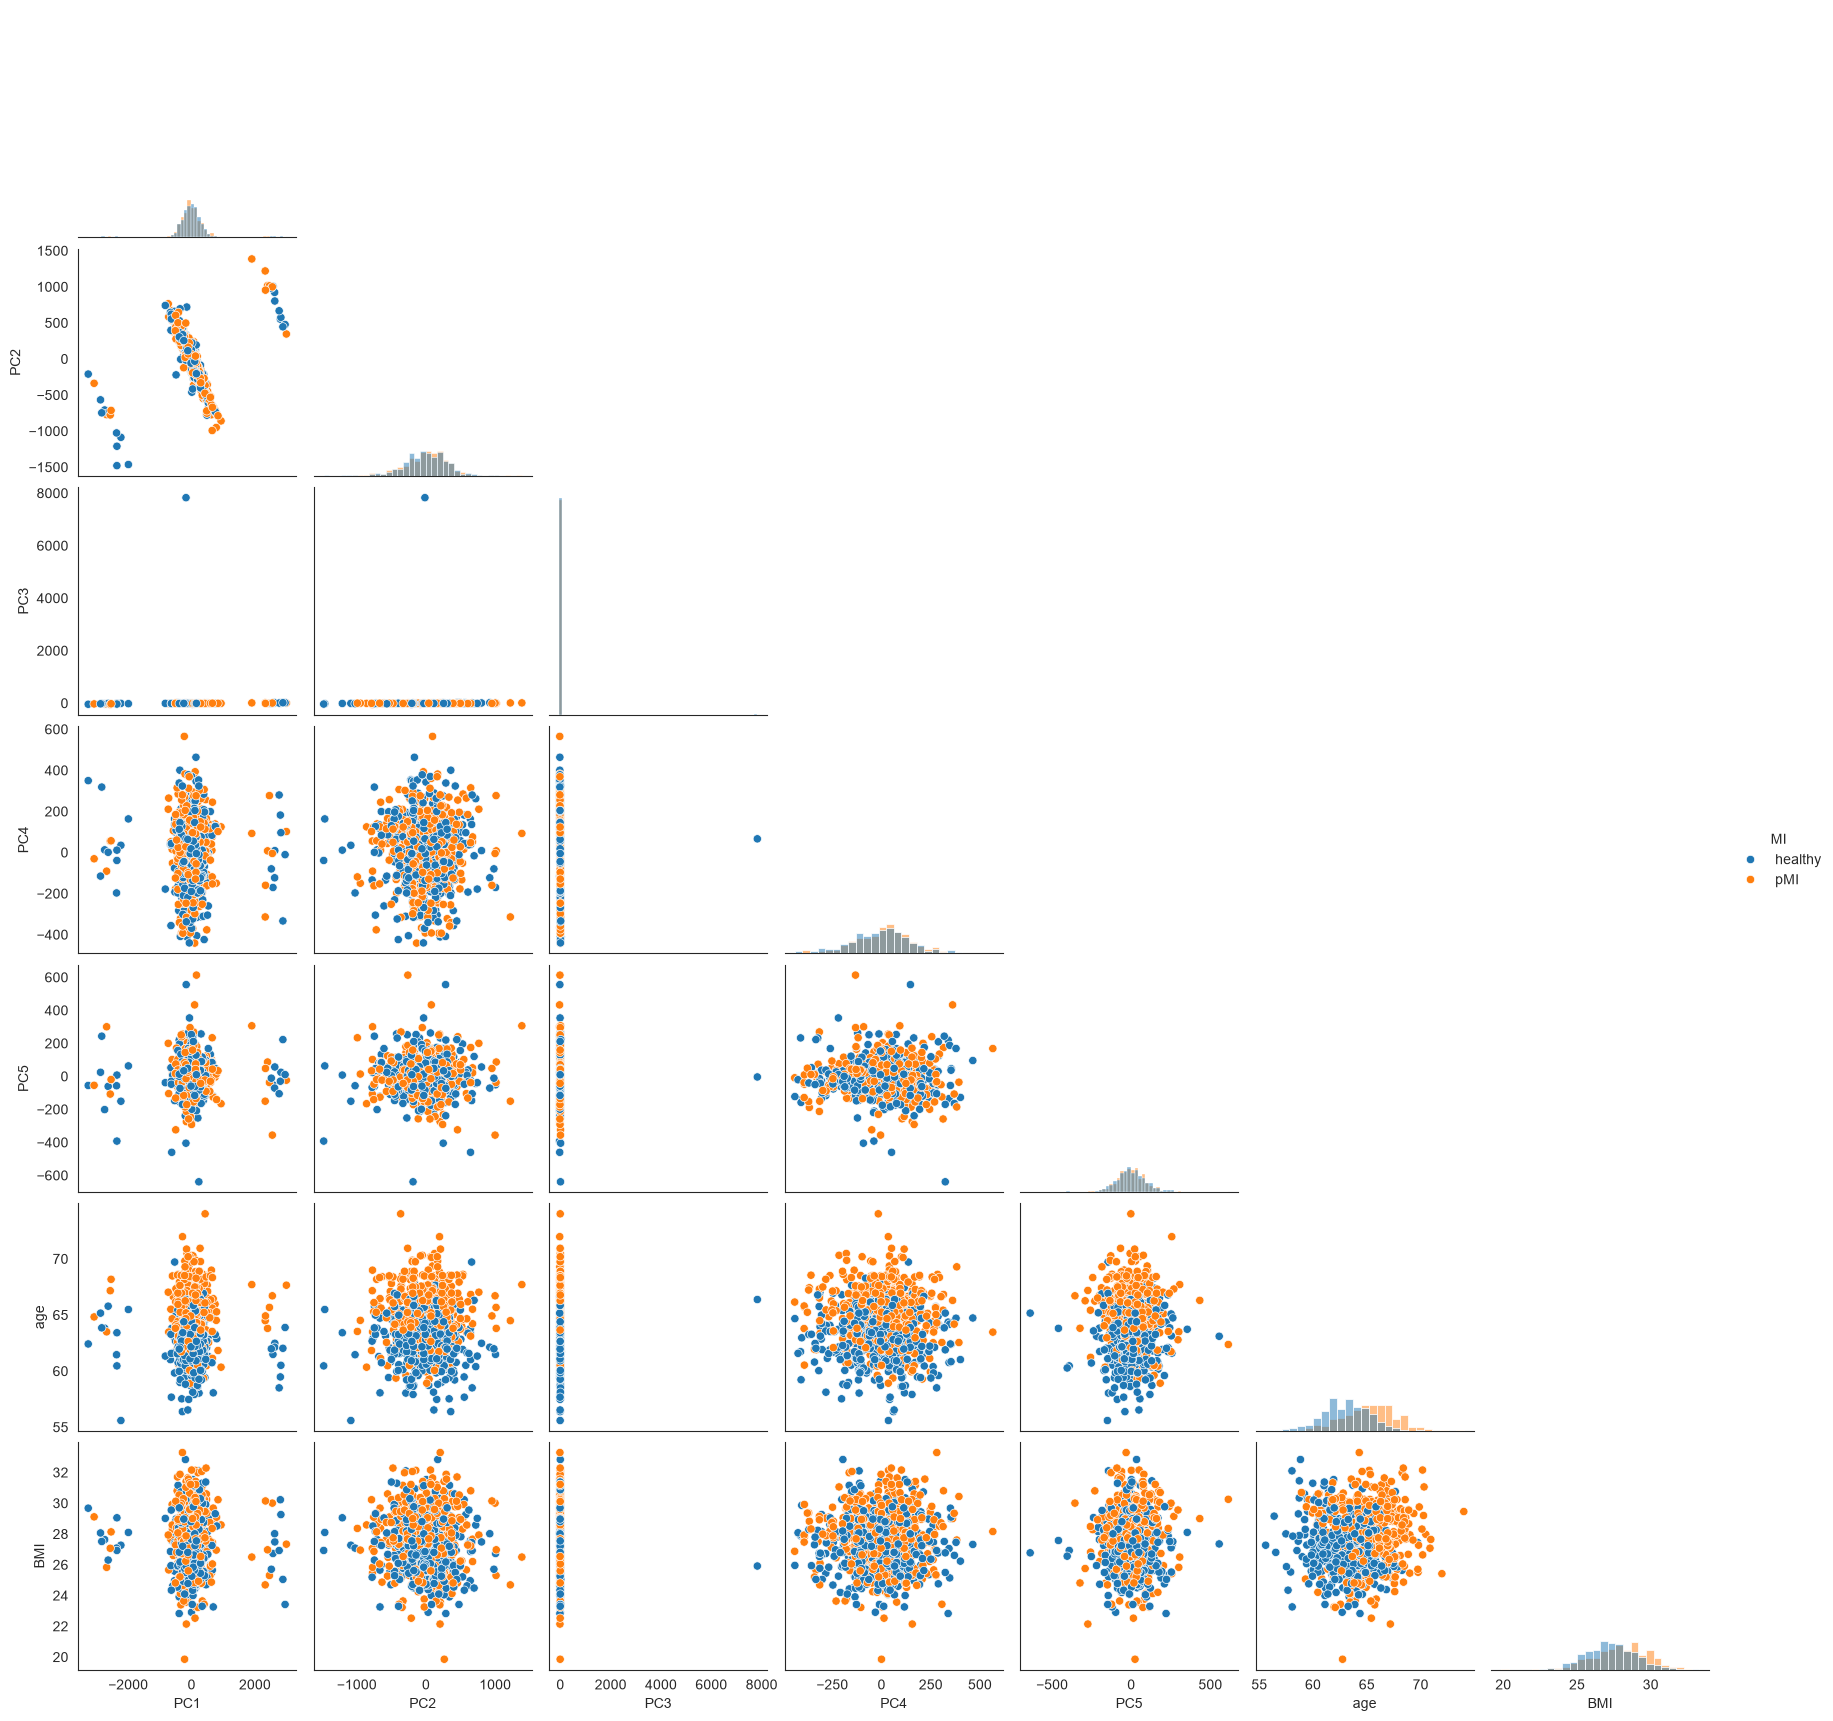

In [68]:
sns.set_style("white")
sns.pairplot(scores_df, diag_kind="hist", corner=True, hue='MI')
plt.show()